# Embedding 对齐与局部覆盖图

按 **Shift+Enter** 从上到下逐单元运行。变量保留在当前内核中；如果修改上游参数，请重新运行其后的单元。

本教程使用固定合成数据，演示软件流程，不提供临床效能结论。需要完整仓库和对应原生安装包；实际源码版本和原生扩展身份请查看本次执行收据。

## 1. 环境与独立输出目录

确认后端为 Rust。后续每步都可以检查中间对象；示例数据生成辅助函数只负责小型输入构造。

In [1]:
from pathlib import Path
import sys, tempfile
from IPython.display import display, Image
# 从 Notebook 所在目录或仓库根目录启动均可。
REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'examples/native/_shared.py').exists()), None)
if REPO is None:
    raise RuntimeError('请先下载完整仓库，并在仓库内启动 Jupyter。')
sys.path.insert(0, str(REPO/'examples/native'))
import ov_radiomics as rad
print(rad.backend_info())
# 每次完整运行使用新目录，避免覆盖已有结果。
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-06_embedding_overlay-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
root = output
print('输出目录:', output)
import hashlib, importlib.metadata, json, platform
runtime = {'interpreter': sys.executable, 'python': platform.python_version(),
           'package_source': rad.__file__, 'backend': rad.backend_info(),
           'packages': {name: importlib.metadata.version(name) for name in
                        ('ov-radiomics', 'numpy', 'pandas', 'matplotlib', 'ipykernel')}}
from ov_radiomics._backend import try_native
extension = try_native()
if extension is None:
    raise RuntimeError('本教程需要真实 Rust 原生扩展。')
runtime['native_path'] = extension.__file__
runtime['native_sha256'] = hashlib.sha256(Path(extension.__file__).read_bytes()).hexdigest()
runtime['package_python_sha256'] = {p.relative_to(Path(rad.__file__).parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                                  for p in sorted(Path(rad.__file__).parent.rglob('*.py'))}
(output/'tutorial-runtime.json').write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding='utf-8')
 
import json
import numpy as np
import pandas as pd
import ov_radiomics as rad
from _shared import output_arguments, task_data, write_json, provenance, plot_small_overlay


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0'}
输出目录: D:\radiomics-tutorial-validation\six-notebooks-final\06_embedding_overlay\artifacts


## 2. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [2]:
(source, features, classes) = task_data('binary')
records = []
values = []
parents = {}
status = {}

## 3. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [3]:
metadata = []
for (_, row) in source.iterrows():
    slide = row['ID'] + '-slide'
    parents[slide] = row.patient_id
    status[slide] = 'provided'
    for position in range(2):
        tile = slide + '-tile' + str(position)
        records.append(dict(patient_id=row.patient_id, slide_id=slide, tile_id=tile, x0=position * 3.0, y0=0.0, width0=4.0, height0=4.0, patch_width=4, patch_height=4, valid_pixels=[0, 0, 4, 4], mpp_x_um=None, mpp_y_um=None, source='synthetic external embedding; source images already decoded elsewhere', qc={}, exclusion_reasons=[]))
        values.append([row[name] + position * 0.01 for name in features])
        metadata.append(dict(ID=tile, patient_id=row.patient_id, slide_id=slide, group=row.group, target=row.target))
permutation = np.arange(len(values))[::-1]
ids = [records[i]['tile_id'] for i in permutation]
matrix = np.asarray(values)[permutation]

## 4. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [4]:
np.save(output / 'embeddings.npy', matrix)
write_json(output / 'embedding-tile-ids.json', ids)
bare = dict(tiles=records, features=None, feature_names=[], slide_patients=parents, slide_status=status)

## 5. 按 tile ID 绑定特征

输入必须明确 tile ID、患者/切片层级及坐标。行数相同不能证明 embedding 对齐。

In [5]:
table = rad.interop.from_arrays(matrix, tile_ids=ids, tiles=bare, feature_names=features)
np.testing.assert_array_equal(table.features, np.asarray(values))
write_json(output / 'tiles.json', table.to_dict())
write_json(output / 'adapter-provenance.json', table.provenance)

## 6. 从 tile 聚合到患者

默认先 tile→slide，再切片等权→patient。查看患者层特征名和身份信息。

In [6]:
aggregate = rad.pathology.aggregate(table, patient_stats=['mean'])
aggregate.patient_features.save(output / 'patient-features.parquet')
aggregate.slide_features.save(output / 'slide-features.csv')
write_json(output / 'aggregation.json', aggregate.report)
outcomes = source[['patient_id', 'group', 'target']].drop_duplicates('patient_id')

## 7. 准备患者级建模表

用患者 ID 做一对一结局连接；明确处理无结局或空结果，不静默补零。

In [7]:
patients = aggregate.patient_features.features.merge(outcomes, left_on='ID', right_on='patient_id', validate='one_to_one')
patient_features = ['patient_mean(slide_tile_mean(' + name + '))' for name in features]
if hasattr(patients, 'head'):
    display(patients.head())

,ID,patient_mean(slide_tile_mean(signal_a)),patient_mean(slide_tile_std(signal_a)),patient_mean(slide_tile_max(signal_a)),patient_mean(slide_tile_q25(signal_a)),patient_mean(slide_tile_q50(signal_a)),patient_mean(slide_tile_q75(signal_a)),patient_mean(slide_tile_mean(signal_b)),patient_mean(slide_tile_std(signal_b)),patient_mean(slide_tile_max(signal_b)),...,patient_mean(slide_tile_q75(noise_a)),patient_mean(slide_tile_mean(noise_b)),patient_mean(slide_tile_std(noise_b)),patient_mean(slide_tile_max(noise_b)),patient_mean(slide_tile_q25(noise_b)),patient_mean(slide_tile_q50(noise_b)),patient_mean(slide_tile_q75(noise_b)),patient_id,group,target
0,binary-P000,1.104270,0.005,1.109270,1.101770,1.104270,1.106770,0.405416,0.005,0.410416,...,1.077444,0.657304,0.005,0.662304,0.654804,0.657304,0.659804,binary-P000,train,negative
1,binary-P001,0.477658,0.005,0.482658,0.475158,0.477658,0.480158,0.148210,0.005,0.153210,...,-0.813034,0.368028,0.005,0.373028,0.365528,0.368028,0.370528,binary-P001,train,positive
2,binary-P002,-1.426737,0.005,-1.421737,-1.429237,-1.426737,-1.424237,0.539176,0.005,0.544176,...,-0.464453,1.756900,0.005,1.761900,1.754400,1.756900,1.759400,binary-P002,train,negative
3,binary-P003,1.282425,0.005,1.287425,1.279925,1.282425,1.284925,1.838162,0.005,1.843162,...,2.203987,2.057831,0.005,2.062831,2.055331,2.057831,2.060331,binary-P003,train,positive
4,binary-P004,0.003730,0.005,0.008730,0.001230,0.003730,0.006230,-0.035190,0.005,-0.030190,...,-0.950572,2.442377,0.005,2.447377,2.439877,2.442377,2.444877,binary-P004,train,negative


## 8. 训练患者级模型

患者级模型输出只代表患者，不能广播到局部病理图。

In [8]:
patient = rad.train_models(patients, 'target', patient_features, classes=classes, positive_label=classes[1], fit_unit='patient', scale='standard', backend='rust', cv=3, inner_cv=2)
patient.save(output / 'patient-model')
rad.evaluate(patient, ci_method=None).to_csv(output / 'patient-metrics.csv', index=False)

## 9. 准备真实 tile 级模型

tile 模型保留每个 tile 的样本身份，但 CV 仍按患者分组。

In [9]:
tiles = pd.DataFrame(metadata)
for (i, name) in enumerate(features):
    tiles[name] = table.features[:, i]
if hasattr(tiles, 'head'):
    display(tiles.head())

,ID,patient_id,slide_id,group,target,signal_a,signal_b,noise_a,noise_b
0,binary-P000-L0-slide-tile0,binary-P000,binary-P000-L0-slide,train,negative,1.189762,0.427544,1.036511,0.684472
1,binary-P000-L0-slide-tile1,binary-P000,binary-P000-L0-slide,train,negative,1.199762,0.437544,1.046511,0.694472
2,binary-P000-L1-slide-tile0,binary-P000,binary-P000-L1-slide,train,negative,1.008778,0.373288,1.103377,0.620137
3,binary-P000-L1-slide-tile1,binary-P000,binary-P000-L1-slide,train,negative,1.018778,0.383288,1.113377,0.630137
4,binary-P001-L0-slide-tile0,binary-P001,binary-P001-L0-slide,train,positive,0.331840,0.193706,-0.945580,0.412253


## 10. 拟合 tile 模型

局部概率图来自实际 tile 级预测；患者内多个 tile 不得跨训练/验证集合。

In [10]:
tile = rad.train_models(tiles, 'target', features, classes=classes, positive_label=classes[1], fit_unit='tile', scoring_unit='patient', scale='standard', backend='rust', cv=3, inner_cv=2)
tile.save(output / 'tile-model')

## 11. 无标签外部预测

移除结局后进行预测，确认保存的填补、缩放、特征与类别顺序被复用。禁止重新拟合外部数据。

In [11]:
external = tiles.loc[tiles.group != 'train'].drop(columns='target')

## 12. 生成局部分数

保留 tile、slide、patient 层级及预测来源；随后按真实坐标回填。

In [12]:
local = tile.predict(external)
write_json(output / 'actual-tile-predictions.json', local.to_dict())
first = external.loc[external.group == 'test'].iloc[0]

## 13. 定义覆盖图坐标

画布使用 level-0 像素边界，x 向右、y 向下。覆盖计数为零的位置透明；重叠部分取平均。

In [13]:
canvas = dict(width=7, height=4, origin0=[0.0, 0.0], pixel_size0=[1.0, 1.0])
stream = rad.pathology.rasterize_predictions(table, local, slide_id=first.slide_id, class_name=classes[1], canvas=canvas, block_size=(3, 2))
stream.save(output / 'actual-tile-score-overlay')
plot_small_overlay(output / 'actual-tile-score-overlay', output / 'actual-tile-score-overlay.png', value_label='Positive-class probability')
try:
    rad.pathology.rasterize_predictions(table, patient.predict(patients.loc[patients.group != 'train'].drop(columns='target')), slide_id=first.slide_id, class_name=classes[1], canvas=canvas)
except ValueError as error:
    write_json(output / 'patient-broadcast-rejected.json', dict(error=str(error)))
else:
    raise AssertionError('Patient probabilities must not be broadcast into local tile maps.')

## 14. 准备数据与保存中间结果

运行并检查本步的数据构造、校验或导出操作。遇到报错时先检查上一单元的输出和对象，而不要跳过校验。

In [14]:
provenance(output, '06_embedding_overlay', embedding_rows=len(matrix), patients=len(patients), alignment='complete tile ID equality, deliberately reversed embedding rows', coordinates='level-0 pixel edges; mpp unknown, no physical units inferred', patient_aggregation='tile→slide then equal-slide patient mean', overlay='actual predictions from a separately fitted tile-unit model; grouped patient CV', optional_wsidata='See docs/interop.md; generation-time geometry snapshot and TableModel tile-ID linkage required. This external-array tutorial does not claim live WSIData runtime validation.')
print(rad.evaluate(tile, ci_method=None).to_string(index=False))
print('Outputs:', output)

model      group   task prediction_unit  n prediction_type          status  positive_n  threshold  accuracy      auc  sensitivity  specificity      ppv      npv  precision   recall       f1    brier  log_loss_eps1e15  average_precision  pr_auc_trapezoidal  ci_low  ci_high
   LR external_A binary         patient  6        external prediction_only         NaN        NaN       NaN      NaN          NaN          NaN      NaN      NaN        NaN      NaN      NaN      NaN               NaN                NaN                 NaN     NaN      NaN
   LR       test binary         patient 12         holdout       evaluated         6.0        0.5  0.583333 0.805556     0.333333     0.833333 0.666667 0.555556   0.666667 0.333333 0.444444 0.210341          0.606019           0.786111            0.754861     NaN      NaN
   LR      train binary         patient 48        apparent       evaluated        24.0        0.5  0.645833 0.723958     0.583333     0.708333 0.666667 0.629630   0.666667 0.583333 

## 查看导出的图与文件

查看图表的坐标、单位和预测层级。输出目录保留完整结果；这里显示前两幅图。

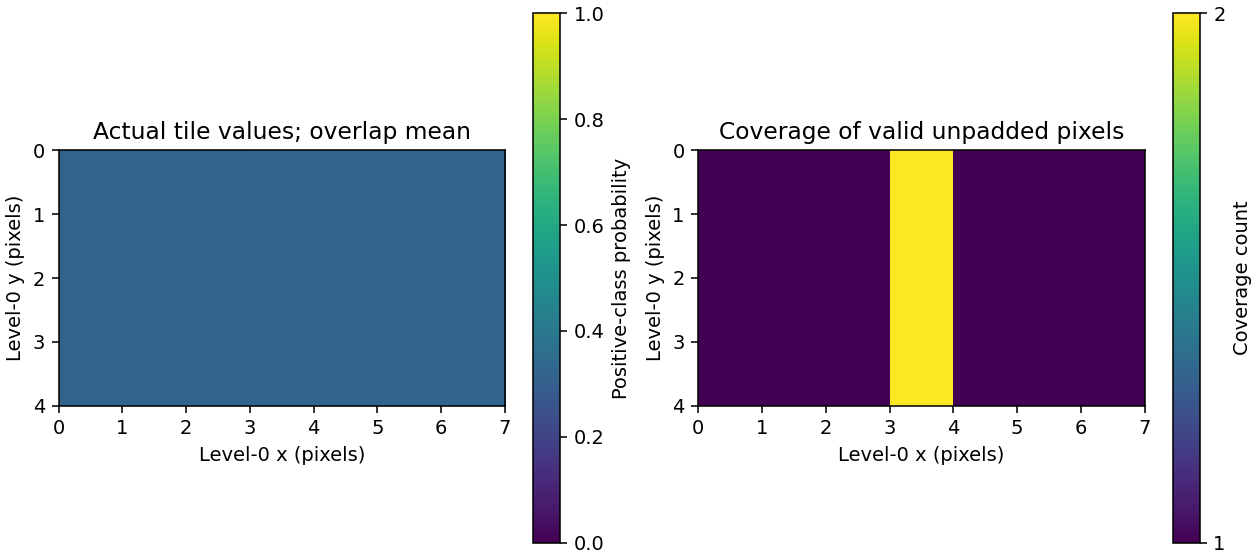

结果文件: ['actual-tile-predictions.json', 'actual-tile-score-overlay', 'actual-tile-score-overlay.png', 'adapter-provenance.json', 'aggregation.json', 'embedding-tile-ids.json', 'embeddings.npy', 'patient-broadcast-rejected.json', 'patient-features.parquet', 'patient-features.parquet.manifest.json', 'patient-metrics.csv', 'patient-model', 'provenance.json', 'slide-features.csv', 'slide-features.csv.manifest.json', 'tile-model', 'tiles.json', 'tutorial-runtime.json']


In [15]:
for figure in sorted(output.glob('*.png'))[:2]:
    display(Image(filename=str(figure)))
print('结果文件:', [p.name for p in sorted(output.iterdir())])

## 换成自己的数据

保持示例的 ID、患者/切片层级与列角色约定，先替换数据读取步骤，再重新运行下游单元。先确认几何、单位、缺失状态和队列重叠；不要用测试集决定阈值或筛选参数。

重新运行全部单元会新建结果目录；只重跑保存单元可能因为文件已存在而报错，这是显式防覆盖行为。